<a href="https://colab.research.google.com/github/AhmadKevin000/PCVK_Ganjil2026/blob/main/Week7_yg_asli%2C_hehe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul P7 - Segmentasi Citra dengan Thresholding

Mata Kuliah : Pengolahan Citra dan Visi Komputer
Nama : _(Ahmad Kevin Malik Zakaria)_
NIM : _(244107020125)_

Isi notebook: D1 global threshold manual, D2 adaptive threshold manual, D3 Otsu manual,
D4 segmentasi berbasis region, D5 segmentasi warna dengan K-Means, dan tugas kelompok OCR.

Notebook ini bisa dijalankan di local (Jupyter/Anaconda) maupun di Google Colab.
Di local, paket yang belum terpasang akan diinstall otomatis di sel berikutnya.
Untuk tesseract yang dipakai di bagian OCR: `brew install tesseract tesseract-lang`
(macOS) atau `sudo apt-get install tesseract-ocr tesseract-ocr-ind` (Linux/Colab).

## 0. Mount Drive dan import library

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception as e:
    print("bukan di Colab ->", e)
    IN_COLAB = False

Mounted at /content/drive


In [2]:
import importlib
import subprocess
import sys

if not IN_COLAB:
    for nama, paket in [("cv2", "opencv-python-headless"),
                        ("sklearn", "scikit-learn"),
                        ("skimage", "scikit-image"),
                        ("pytesseract", "pytesseract")]:
        try:
            importlib.import_module(nama)
        except ImportError:
            print("install", paket)
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket])
    print("paket siap")

In [3]:
import os
import math
import warnings
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from numpy.lib.stride_tricks import sliding_window_view

%matplotlib inline
np.random.seed(42)
warnings.filterwarnings("ignore")

print("Python :", sys.version.split()[0])
print("OpenCV :", cv.__version__)
print("NumPy  :", np.__version__)

Python : 3.13.16
OpenCV : 5.0.0
NumPy  : 2.1.3


### Memuat gambar

Folder gambar di Google Drive: `/content/drive/MyDrive/Matkul Sem 5/PCVK/Images`.
Kalau dijalankan di local, gambar dicari di folder kerja dan subfolder `Images`.

In [4]:
IMG_DIR = "/content/drive/MyDrive/Matkul Sem 5/PCVK/Images"

_CWD = os.getcwd()
_CARI = [IMG_DIR, "/content", _CWD, os.path.join(_CWD, "Images"),
         os.path.join(os.path.dirname(_CWD), "Images")]


def load_image(*nama_file):
    for nama in nama_file:
        for folder in _CARI:
            path = os.path.join(folder, nama)
            if os.path.exists(path):
                img = cv.imread(path)
                if img is not None:
                    print("terbaca:", path, img.shape)
                    return img
    from google.colab import files
    print("file tidak ditemukan, silakan upload:", nama_file[0])
    uploaded = files.upload()
    for name in uploaded:
        img = cv.imread(name)
        if img is not None:
            print("terbaca:", name, img.shape)
            return img
    raise FileNotFoundError(nama_file[0])


gradient = load_image("gradient.jpg")
sudoku   = load_image("sudoku-original.jpg")
lena_lc2 = load_image("lena_gs_lc2.jpg")
noisy2   = load_image("noisy2.png")
lily     = load_image("lily.jpg")
ktp      = load_image("ktp1.jpg", "ktp.jpg", "KTP_Fulan.jpg")

terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/gradient.jpg (540, 960, 3)
terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/sudoku-original.jpg (423, 419, 3)
terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/lena_gs_lc2.jpg (512, 512, 3)
terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/noisy2.png (256, 512, 3)
terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/lily.jpg (599, 623, 3)
terbaca: /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/ktp1.jpg (458, 694, 3)


---
# D1. Global Threshold

Lima jenis global threshold dibuat manual dengan NumPy, ambang 127 dan 200.

| Jenis | Jika piksel > thresh | Jika piksel <= thresh |
|---|---|---|
| BINARY | maxval | 0 |
| BINARY_INV | 0 | maxval |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

In [5]:
def thresh_binary(img, thresh, maxval=255):
    out = img.copy()
    out[img > thresh] = maxval
    out[img <= thresh] = 0
    return out


def thresh_binary_inv(img, thresh, maxval=255):
    out = img.copy()
    out[img > thresh] = 0
    out[img <= thresh] = maxval
    return out


def thresh_trunc(img, thresh, maxval=255):
    out = img.copy()
    out[img > thresh] = thresh
    return out


def thresh_tozero(img, thresh, maxval=255):
    out = img.copy()
    out[img <= thresh] = 0
    return out


def thresh_tozero_inv(img, thresh, maxval=255):
    out = img.copy()
    out[img > thresh] = 0
    return out

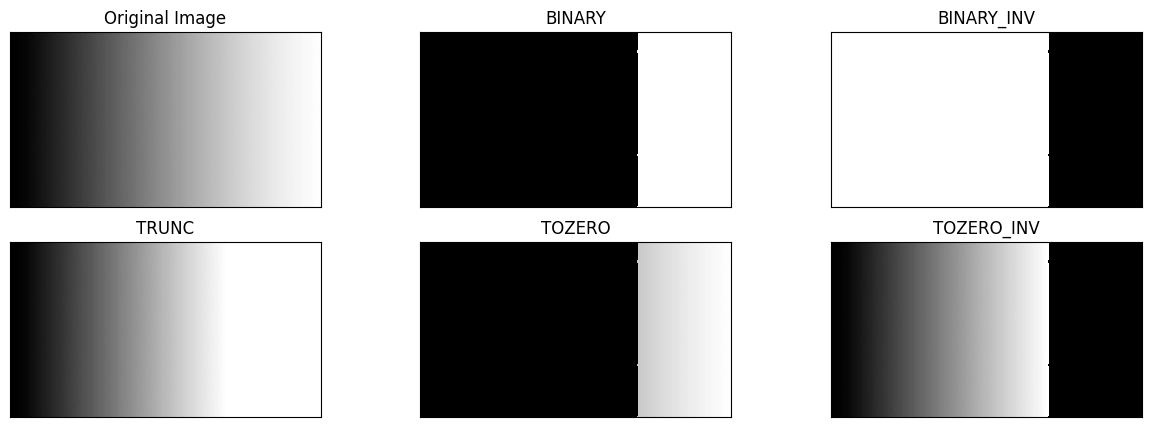

In [6]:
img = cv.cvtColor(gradient, cv.COLOR_BGR2GRAY)
thresh = 200
maxval = 255

thresh1 = thresh_binary(img, thresh, maxval)
thresh2 = thresh_binary_inv(img, thresh, maxval)
thresh3 = thresh_trunc(img, thresh, maxval)
thresh4 = thresh_tozero(img, thresh, maxval)
thresh5 = thresh_tozero_inv(img, thresh, maxval)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Hasilnya sesuai rumus masing-masing. BINARY menyisakan putih hanya di area yang nilainya
di atas 200, BINARY_INV kebalikannya, TRUNC memotong semua nilai di atas 200 menjadi tepat
200, sedangkan TOZERO dan TOZERO_INV mempertahankan nilai asli hanya di satu sisi ambang.

---
# D2. Adaptive Threshold

Setiap piksel memakai ambangnya sendiri yang dihitung dari jendela lokal:

T(x, y) = rata-rata lokal (x, y) - C

Dipakai global threshold manual 127, ukuran jendela 11 x 11, C = 2, dan sigma = 2.
Rata-rata lokal dihitung dengan integral image, sedangkan Gaussian dihitung dengan
konvolusi separabel, jadi tidak memakai cv.threshold, cv.adaptiveThreshold, maupun
fungsi filter siap pakai.

In [7]:
def box_mean(img, b):
    r = b // 2
    p = np.pad(img.astype(np.float64), r, mode='edge')
    integral = np.pad(p.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    H, W = img.shape
    y = np.arange(H)[:, None]
    x = np.arange(W)[None, :]
    jumlah = integral[y + b, x + b] - integral[y, x + b] - integral[y + b, x] + integral[y, x]
    return jumlah / (b * b)


def gauss_kernel(size, sigma):
    x = np.arange(size) - (size - 1) / 2.0
    k = np.exp(-(x ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def conv1d(img, k, axis):
    r = len(k) // 2
    pad = ((0, 0), (r, r)) if axis == 1 else ((r, r), (0, 0))
    p = np.pad(img.astype(np.float64), pad, mode='reflect')
    w = sliding_window_view(p, len(k), axis=axis)
    return (w * k).sum(axis=-1)


def gauss_blur(img, size, sigma):
    k = gauss_kernel(size, sigma)
    return conv1d(conv1d(img, k, 1), k, 0)


def adaptive_mean(gray, b, C):
    lokal = box_mean(gray, b)
    return ((gray > (lokal - C)) * 255).astype(np.uint8)


def adaptive_gaussian(gray, b, C, sigma):
    lokal = gauss_blur(gray, b, sigma)
    return ((gray > (lokal - C)) * 255).astype(np.uint8)

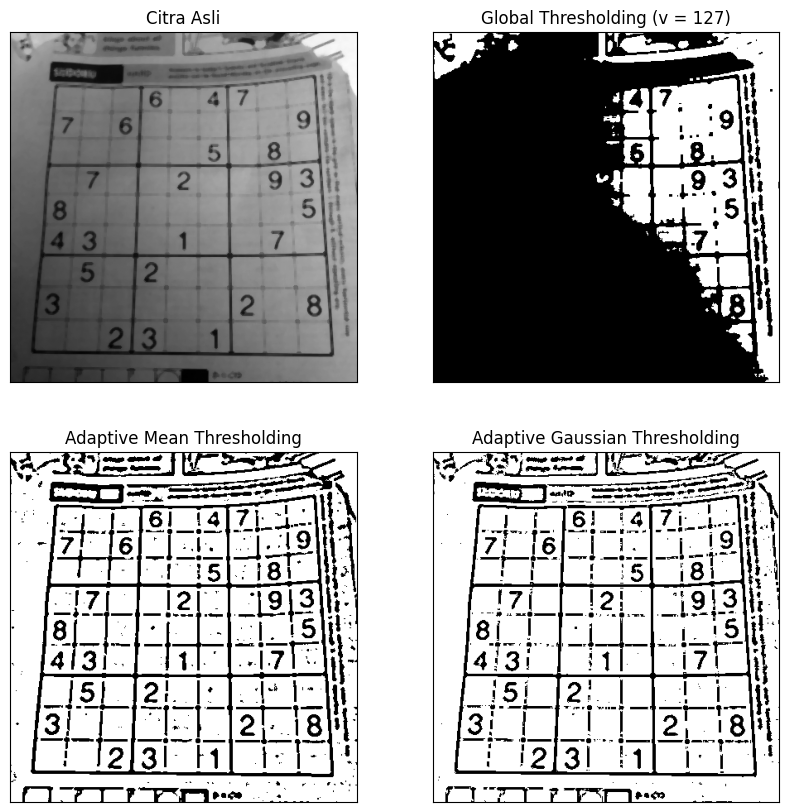

In [8]:
citra = cv.medianBlur(sudoku, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127
th1 = ((gray > thresh) * 255).astype(np.uint8)
th2 = adaptive_mean(gray, 11, 2)
th3 = adaptive_gaussian(gray, 11, 2, 2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(10, 10))
for i in range(len(citra2)):
    plt.subplot(2, 2, i + 1), plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Ambang global 127 gagal pada citra ini karena seluruh papan Sudoku nilainya di atas 127,
sehingga hasilnya putih semua dan tulisan hilang. Adaptive threshold berhasil karena tiap
piksel dibandingkan dengan rata-rata lingkungannya sendiri. Goresan angka yang lebih gelap
dari sekitarnya menjadi hitam, dan kertas yang lebih terang menjadi putih, walaupun
kecerahan absolutnya berbeda antara sisi terang dan sisi gelap.

Adaptive mean memakai bobot rata di seluruh jendela 11 x 11 sehingga tepi angka sedikit
kasar, sedangkan adaptive Gaussian memberi bobot lebih besar pada piksel dekat pusat
sehingga tepinya lebih halus. Padding memakai reflect agar hasilnya sama dengan
cv.adaptiveThreshold.

---
# D3. Otsu Threshold

Otsu mencari ambang t yang memaksimalkan variansi antar kelas, yang sama dengan
meminimalkan variansi dalam kelas:

sigma_b^2(t) = w0(t) * w1(t) * [mu0(t) - mu1(t)]^2

dengan w0 dan w1 bobot tiap kelas, mu0 dan mu1 rata-rata intensitas tiap kelas.

In [9]:
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

In [10]:
contoh = np.array([[0, 0, 0, 0, 0, 0],
                   [0, 0, 1, 1, 1, 1],
                   [1, 1, 1, 2, 2, 3],
                   [3, 3, 3, 3, 3, 4],
                   [4, 4, 4, 4, 4, 4],
                   [4, 4, 5, 5, 5, 5]], dtype=np.uint8)
print(contoh)
otsu(contoh)

[[0 0 0 0 0 0]
 [0 0 1 1 1 1]
 [1 1 1 2 2 3]
 [3 3 3 3 3 4]
 [4 4 4 4 4 4]
 [4 4 5 5 5 5]]
3


(array([[  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   3],
        [  3,   3,   3,   3,   3, 255],
        [255, 255, 255, 255, 255, 255],
        [255, 255, 255, 255, 255, 255]], dtype=uint8),
 np.int64(3))

### 3A. Otsu manual pada lena_gs_lc2.jpg

93


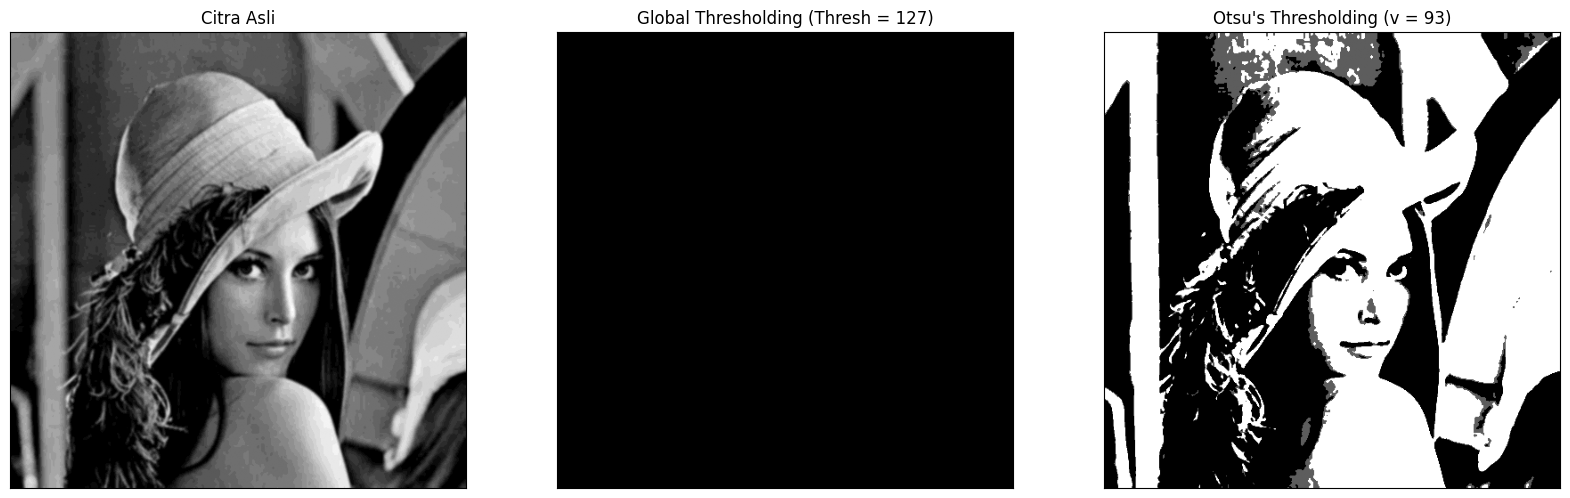

In [11]:
img = cv.cvtColor(lena_lc2, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

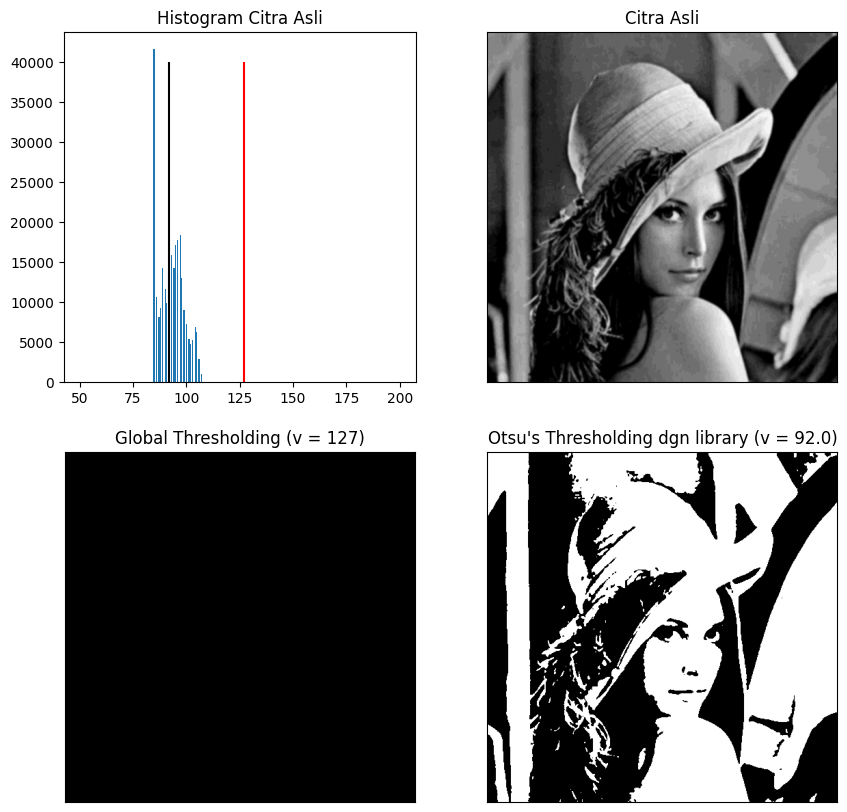

Otsu manual : 93
Otsu library: 92.0
rentang intensitas citra: 85 - 108


In [12]:
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = ("Otsu's Thresholding dgn library (v = ") + str(ret2) + ")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1), plt.hist(blur.ravel(), 256, [50, 200])
plt.vlines(ret, 0, 40000, colors='red')
plt.vlines(ret2, 0, 40000, colors='black')
plt.title('Histogram Citra Asli')
for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

print("Otsu manual :", otsu_thresh)
print("Otsu library:", ret2)
print("rentang intensitas citra:", blur.min(), "-", blur.max())

**Pertanyaan: mengapa hasil Binary Thresholding semua bernilai 0 atau hitam?**

Seluruh nilai piksel lena_gs_lc2.jpg berada di rentang 85 sampai 108, sedangkan ambang
yang dipakai 127. Tidak ada piksel yang nilainya lebih besar dari 127, jadi semua piksel
masuk kelas background dan hasilnya hitam semua.

Supaya gambar Lena masih terlihat, ambang harus berada di dalam rentang intensitasnya,
misalnya 96 atau 97. Otsu menghitung ambangnya sendiri dari histogram dan memilih t = 93,
sehingga objek dan latar masih terpisah. Hasil Otsu manual dan hasil Otsu library sama,
yang berbeda hanya cara penulisannya: library memakai aturan piksel putih jika f > t,
sedangkan fungsi di atas memakai f > final_thresh dengan final_thresh hasil iterasi.

### 3B. Otsu vs global threshold pada citra KTP

166


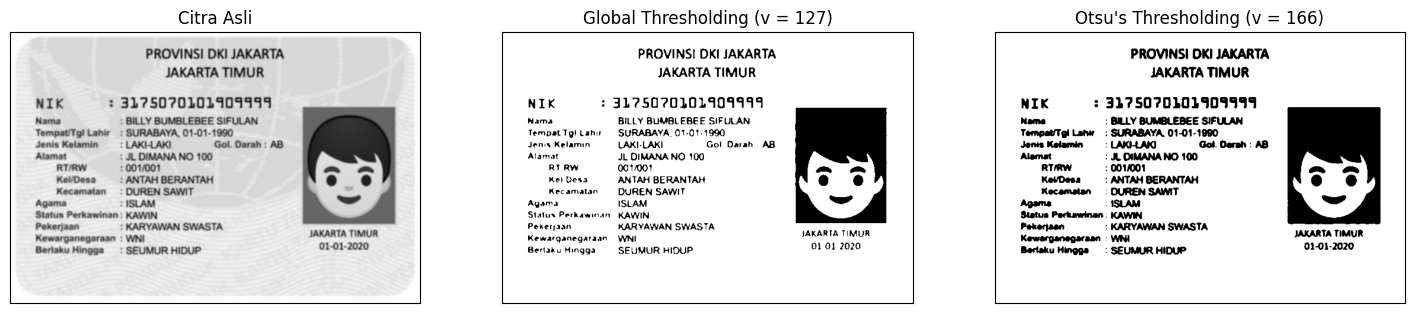

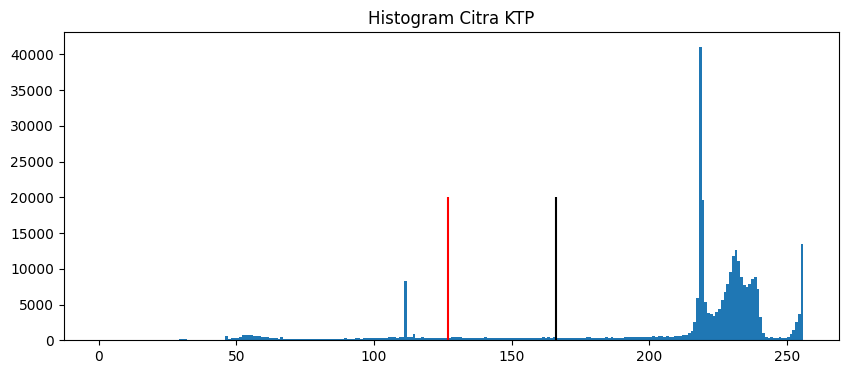

rentang intensitas KTP: 15 - 255
Otsu manual : 166


In [13]:
img = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(img, (5, 5), 0)

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, 127, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
          "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"]
citra4 = [blur, th1, otsu_biner]

plt.figure(figsize=(18, 6))
for i in range(len(citra4)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra4[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), 256, [0, 256])
plt.vlines(127, 0, 20000, colors='red')
plt.vlines(otsu_thresh, 0, 20000, colors='black')
plt.title('Histogram Citra KTP')
plt.show()

print("rentang intensitas KTP:", blur.min(), "-", blur.max())
print("Otsu manual :", otsu_thresh)

Histogram KTP tidak bimodal sempurna karena ada latar terang, tulisan gelap, dan foto.
Ambang global 127 seringkali jatuh di tengah puncak latar sehingga tulisan tipis ikut
hilang. Otsu memilih ambang dari histogram citra itu sendiri sehingga tulisan lebih
terjaga, dan hasil inilah yang dipakai sebagai masukan OCR pada bagian tugas kelompok.

### Pengayaan: pengaruh Gaussian filter sebelum Otsu (noisy2.png)

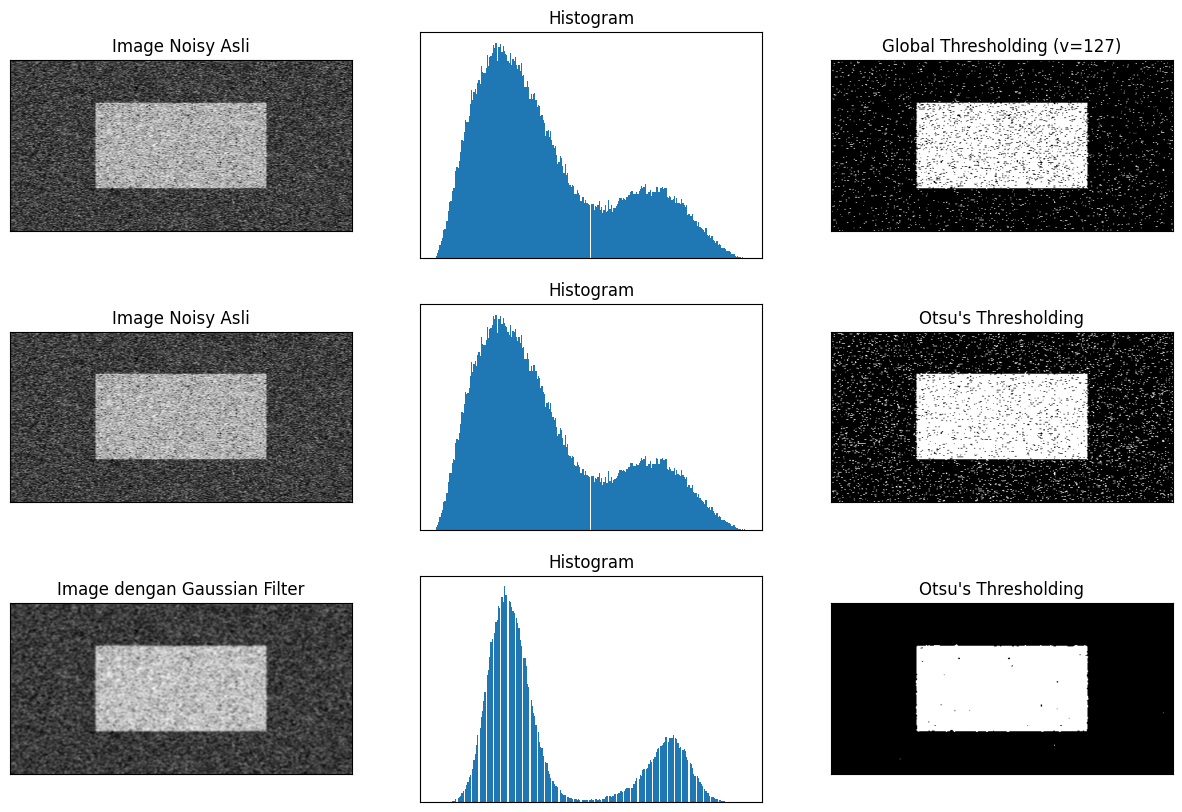

Otsu tanpa filter  : 114.0
Otsu setelah filter: 117.0


In [14]:
img = cv.cvtColor(noisy2, cv.COLOR_BGR2GRAY)

# Global Thresholding
ret1, th1 = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
# Otsu's thresholding
ret2, th2 = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
# Otsu's thresholding setelah dilakukan Gaussian filtering
blur = cv.GaussianBlur(img, (5, 5), 0)
ret3, th3 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

images = [img, 0, th1,
          img, 0, th2,
          blur, 0, th3]
titles = ['Image Noisy Asli', 'Histogram', 'Global Thresholding (v=127)',
          'Image Noisy Asli', 'Histogram', "Otsu's Thresholding",
          'Image dengan Gaussian Filter', 'Histogram', "Otsu's Thresholding"]

plt.figure(figsize=(15, 10))
for i in range(3):
    plt.subplot(3, 3, i * 3 + 1), plt.imshow(images[i * 3], 'gray')
    plt.title(titles[i * 3]), plt.xticks([]), plt.yticks([])
    plt.subplot(3, 3, i * 3 + 2), plt.hist(images[i * 3].ravel(), 256)
    plt.title(titles[i * 3 + 1]), plt.xticks([]), plt.yticks([])
    plt.subplot(3, 3, i * 3 + 3), plt.imshow(images[i * 3 + 2], 'gray')
    plt.title(titles[i * 3 + 2]), plt.xticks([]), plt.yticks([])
plt.show()

print("Otsu tanpa filter  :", ret2)
print("Otsu setelah filter:", ret3)

Histogram noisy2.png bergerigi karena noise sehingga ambang Otsu bisa jatuh di lembah
yang salah. Setelah dihaluskan dengan Gaussian filter, histogram lebih mulus dan hasil
segmentasinya lebih bersih. Jadi filter dulu sebelum Otsu memang membantu.

---
# D4. Segmentasi Berbasis Region

Citra data.coins() dipakai karena objeknya jelas, latarnya cukup homogen, dan ada koin
yang saling bersentuhan. Tiga seed yang dipakai: satu di dalam koin, satu di latar, dan
satu tepat di tepi koin. Masing-masing dijalankan dengan T = 5, 20, dan 60.

In [15]:
from skimage import data
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops
from skimage.segmentation import flood
from scipy import ndimage as ndi

coins = data.coins()
print(coins.shape, coins.min(), coins.max())

mask = coins > threshold_otsu(coins)
H, W = coins.shape
kandidat = []
for r in regionprops(label(mask)):
    y0, x0, y1, x1 = r.bbox
    if r.area > 1500 and y0 > 0 and x0 > 0 and y1 < H and x1 < W:
        kandidat.append(r)
koin = max(kandidat, key=lambda r: r.area)

seed_koin = tuple(int(v) for v in koin.centroid)

erosi = ndi.binary_erosion(koin.image)
tepi = np.argwhere(koin.image & ~erosi)
seed_tepi = (int(tepi[len(tepi) // 2][0]) + koin.bbox[0],
             int(tepi[len(tepi) // 2][1]) + koin.bbox[1])

seed_latar = (int(H * 0.5), 5)

print("koin area", int(koin.area), "bbox", koin.bbox)
print("seed koin ", seed_koin, coins[seed_koin])
print("seed latar", seed_latar, coins[seed_latar])
print("seed tepi ", seed_tepi, coins[seed_tepi])

(303, 384) 1 252
koin area 3062 bbox (156, 315, 218, 380)
seed koin  (186, 347) 150
seed latar (151, 5) 79
seed tepi  (193, 316) 130


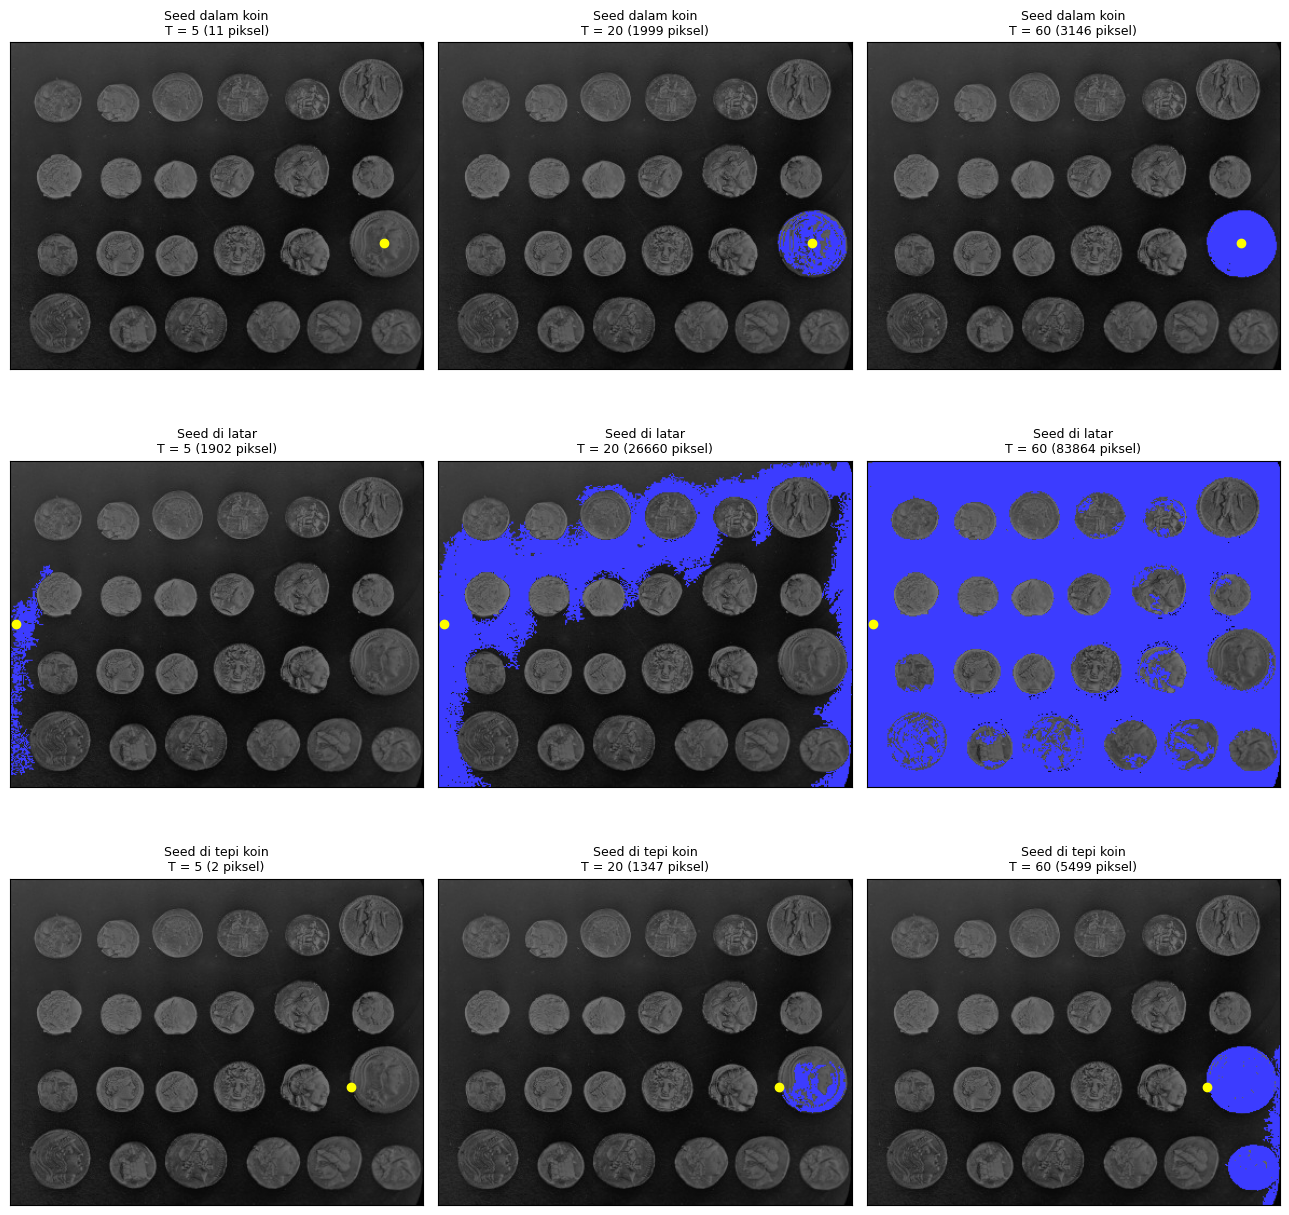

In [16]:
def region_growing(img, seed, T):
    H, W = img.shape
    visited = np.zeros((H, W), bool)
    region = np.zeros((H, W), bool)

    tetangga = [(-1, -1), (-1, 0), (-1, 1),
                (0, -1), (0, 1),
                (1, -1), (1, 0), (1, 1)]

    nilai_seed = float(img[seed])
    tumpukan = [seed]
    visited[seed] = True

    while tumpukan:
        i, j = tumpukan.pop()
        region[i, j] = True
        for di, dj in tetangga:
            ni, nj = i + di, j + dj
            if 0 <= ni < H and 0 <= nj < W and not visited[ni, nj]:
                visited[ni, nj] = True
                if abs(float(img[ni, nj]) - nilai_seed) <= T:
                    tumpukan.append((ni, nj))
    return region


def overlay(gray, mask):
    base = (gray * 0.5).astype(np.uint8)
    rgb = cv.cvtColor(base, cv.COLOR_GRAY2BGR)
    rgb[mask] = (255, 60, 60)
    return rgb


seeds = [('Seed dalam koin', seed_koin),
         ('Seed di latar', seed_latar),
         ('Seed di tepi koin', seed_tepi)]
Ts = [5, 20, 60]

plt.figure(figsize=(13, 13))
for r, (nama, s) in enumerate(seeds):
    for c, T in enumerate(Ts):
        m = region_growing(coins, s, T)
        plt.subplot(3, 3, r * 3 + c + 1)
        plt.imshow(cv.cvtColor(overlay(coins, m), cv.COLOR_BGR2RGB))
        plt.plot(s[1], s[0], 'o', color='yellow', markersize=6)
        plt.title(nama + '\nT = ' + str(T) + ' (' + str(int(m.sum())) + ' piksel)', fontsize=9)
        plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

T = 5 | region_growing: 11 | flood: 11 | sama: True
T = 20 | region_growing: 1999 | flood: 1999 | sama: True
T = 60 | region_growing: 3146 | flood: 3146 | sama: True


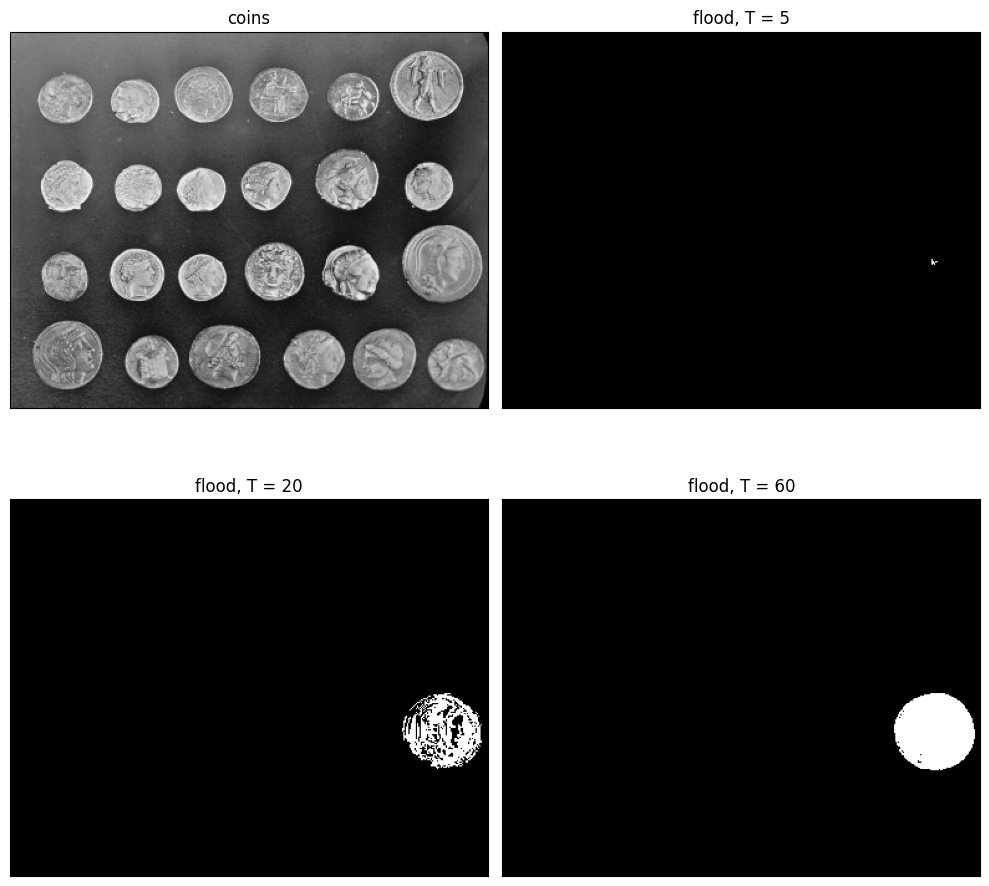

In [17]:
# pembanding: skimage.segmentation.flood()
for T in [5, 20, 60]:
    manual = region_growing(coins, seed_koin, T)
    flood_mask = flood(coins, seed_koin, tolerance=T)
    print("T =", T, "| region_growing:", int(manual.sum()),
          "| flood:", int(flood_mask.sum()), "| sama:", np.array_equal(manual, flood_mask))

plt.figure(figsize=(10, 10))
for i, T in enumerate([5, 20, 60]):
    plt.subplot(2, 2, i + 2)
    plt.imshow(flood(coins, seed_koin, tolerance=T), cmap='gray')
    plt.title('flood, T = ' + str(T))
    plt.xticks([]), plt.yticks([])
plt.subplot(2, 2, 1), plt.imshow(coins, cmap='gray')
plt.title('coins'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

Pengaruh posisi seed dan nilai T terlihat dari grid di atas:

- Seed di dalam koin: T = 5 hanya menutupi bercak kecil di sekitar seed, T = 20 sudah
  menutupi badan koin, T = 60 melebar keluar koin dan menyentuh latar.
- Seed di latar: T = 5 hanya beberapa piksel, T = 20 sudah menyapu sebagian latar,
  T = 60 hampir seluruh latar ikut terambil.
- Seed di tepi koin: T = 5 hampir tidak tumbuh, T = 20 mulai menyusur tepi, T = 60 bocor
  ke latar.

T yang terlalu kecil menghasilkan region kecil-kecil (over-segmentation), T yang terlalu
besar membuat region bocor ke objek lain (under-segmentation). Nilai seed juga menentukan
karena seed di tepi koin nilainya berada di antara koin dan latar. Fungsi flood() dari
skimage menerima piksel terhubung yang selisihnya masih dalam toleransi terhadap nilai
seed, jadi hasilnya sama dengan region_growing untuk seed dan T yang sama.

---
# D5. Segmentasi Warna dengan K-Means

K-Means mengelompokkan piksel berdasarkan kemiripan warna, tanpa memperhatikan posisinya.
Citra hasilnya hanya berisi K warna saja.

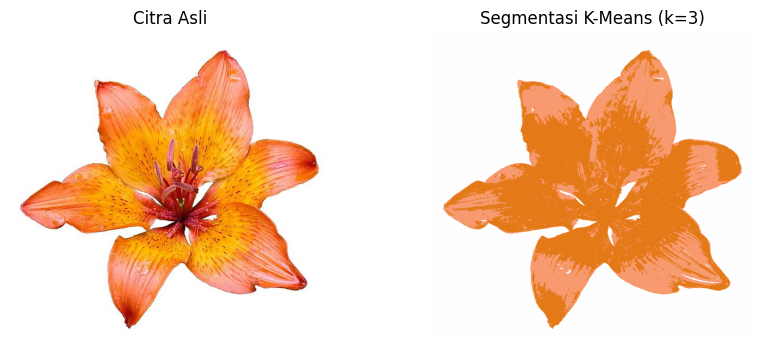

In [18]:
from sklearn.cluster import KMeans

filename = 'lily.jpg'
img = cv.cvtColor(lily, cv.COLOR_BGR2RGB)

Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')
plt.show()

cluster 4 biru: [244 227 198]


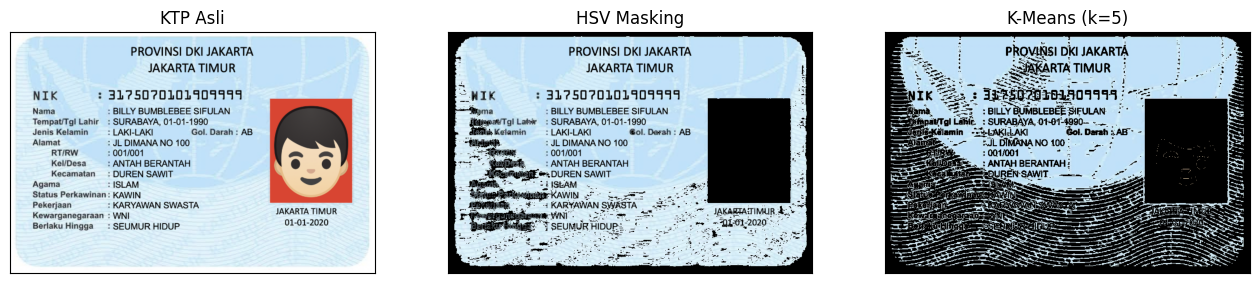

piksel HSV : 74.6 %
piksel K-Means: 47.5 %


In [19]:
img = ktp.copy()
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
hasil_hsv = np.zeros_like(img)
hasil_hsv[kelompok_biru] = img[kelompok_biru]

Z = img.reshape((-1, 3))
Z = np.float32(Z)
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
centers_hsv = cv.cvtColor(centers.reshape(1, k, 3), cv.COLOR_BGR2HSV)[0]
labels_img = labels.reshape(img.shape[:2])

mask_biru = np.zeros(img.shape[:2], bool)
for i in range(k):
    h, s, v = centers_hsv[i]
    if 85 <= h <= 130 and s >= 25 and v >= 40:
        print("cluster", i, "biru:", centers[i])
        mask_biru |= (labels_img == i)

hasil_kmeans = np.zeros_like(img)
hasil_kmeans[mask_biru] = img[mask_biru]

titles = ['KTP Asli', 'HSV Masking', 'K-Means (k=5)']
citra5 = [img, hasil_hsv, hasil_kmeans]

plt.figure(figsize=(16, 6))
for i in range(len(citra5)):
    plt.subplot(1, 3, i + 1), plt.imshow(cv.cvtColor(citra5[i], cv.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

print("piksel HSV :", round(kelompok_biru[0].size / img.shape[0] / img.shape[1] * 100, 1), "%")
print("piksel K-Means:", round(mask_biru.mean() * 100, 1), "%")

HSV masking menyeleksi per piksel sehingga hasilnya mengikuti bentuk latar biru KTP.
K-Means mengelompokkan warna secara global, cluster yang pusatnya masuk rentang biru
dipertahankan, sehingga hasilnya lebih rata tetapi bisa ikut mengambil bagian gambar
yang warnanya mirip biru.

---
# Tugas Kelompok: OCR KTP

Membandingkan pembacaan teks dengan pytesseract pada tiga citra: berwarna asli, hasil
Otsu thresholding, dan hasil adaptive thresholding. Ketiganya memakai ukuran yang sama,
bahasa dan psm yang sama, serta batas confidence yang sama (> 60).

In [20]:
import platform
import shutil
import subprocess
import sys

if shutil.which("tesseract") is None:
    if platform.system() == "Darwin" and shutil.which("brew"):
        subprocess.run(["brew", "install", "tesseract", "tesseract-lang"])
    elif shutil.which("apt-get"):
        subprocess.run(["sudo", "apt-get", "install", "-y",
                        "tesseract-ocr", "tesseract-ocr-ind"])

try:
    import pytesseract
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytesseract"])
    import pytesseract

for path in ["/opt/homebrew/bin/tesseract", "/usr/local/bin/tesseract",
             "/usr/bin/tesseract"]:
    if os.path.exists(path):
        pytesseract.pytesseract.tesseract_cmd = path
        break

LANGS = pytesseract.get_languages(config="")
OCR_LANG = "ind" if "ind" in LANGS else "eng"
OCR_PSM = 6

print("tesseract:", pytesseract.get_tesseract_version())
print("bahasa   :", OCR_LANG, "| psm:", OCR_PSM)

tesseract: 5.3.4
bahasa   : eng | psm: 6


157


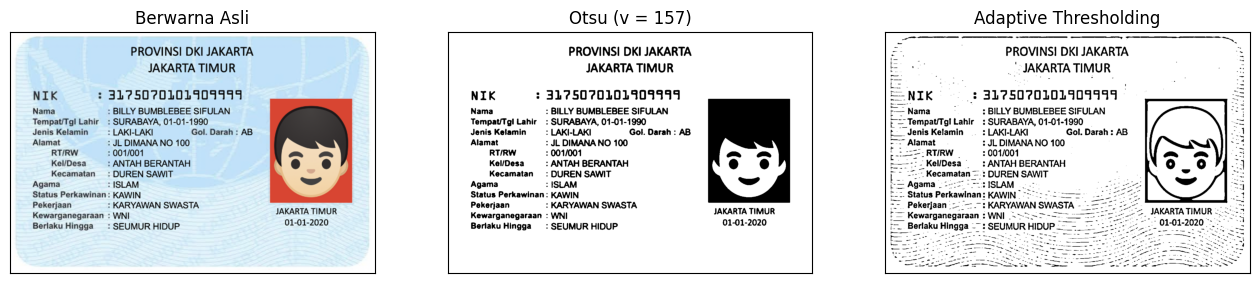

In [21]:
# tiga citra yang dibandingkan, ukurannya disamakan
SCALE = 2.0
ktp_big = cv.resize(ktp, None, fx=SCALE, fy=SCALE, interpolation=cv.INTER_CUBIC)
ktp_gray = cv.cvtColor(ktp_big, cv.COLOR_BGR2GRAY)

# 1. citra berwarna asli
citra_warna = ktp_big.copy()

# 2. hasil Otsu thresholding
blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)
citra_otsu, otsu_thresh = otsu(blur)

# 3. hasil adaptive thresholding
citra_adaptive = adaptive_gaussian(ktp_gray, 31, 10, 8.0)

titles = ['Berwarna Asli', "Otsu (v = " + str(otsu_thresh) + ")", 'Adaptive Thresholding']
citra6 = [citra_warna, citra_otsu, citra_adaptive]

plt.figure(figsize=(16, 6))
for i in range(len(citra6)):
    if citra6[i].ndim == 2:
        plt.subplot(1, 3, i + 1), plt.imshow(citra6[i], 'gray')
    else:
        plt.subplot(1, 3, i + 1), plt.imshow(cv.cvtColor(citra6[i], cv.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

In [22]:
def ocr_text(img):
    if img.ndim == 2:
        rgb = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
    else:
        rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    return pytesseract.image_to_string(rgb, lang=OCR_LANG, config="--oem 3 --psm " + str(OCR_PSM))


citra_uji = {'Berwarna': citra_warna, 'Otsu': citra_otsu, 'Adaptive': citra_adaptive}
teks = {}
for nama, im in citra_uji.items():
    teks[nama] = ocr_text(im)
    print("=" * 60)
    print("OCR", nama)
    print("=" * 60)
    print(teks[nama].strip())
    print()

OCR Berwarna
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK > 31750701019099599
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tg! Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH ' /

Kecamatan : DUREN SAWIT
Agama > ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga :SEUMURHIDUP 01-01-2020

OCR Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK > 3175070101909999
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama > ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Beriaku Hingga : SEUMUR HIDUP 01-01-2020

OCR Adaptive
9
© ., PROVINS! DKI JAKARTA S
i mo . © JAKARTA TIMUR ot
= ae a ; 3 2S
E-NIK 2: 3175070101909995 =
r—— Nama : : BILLY BUMBLEBEE SIFULAN os


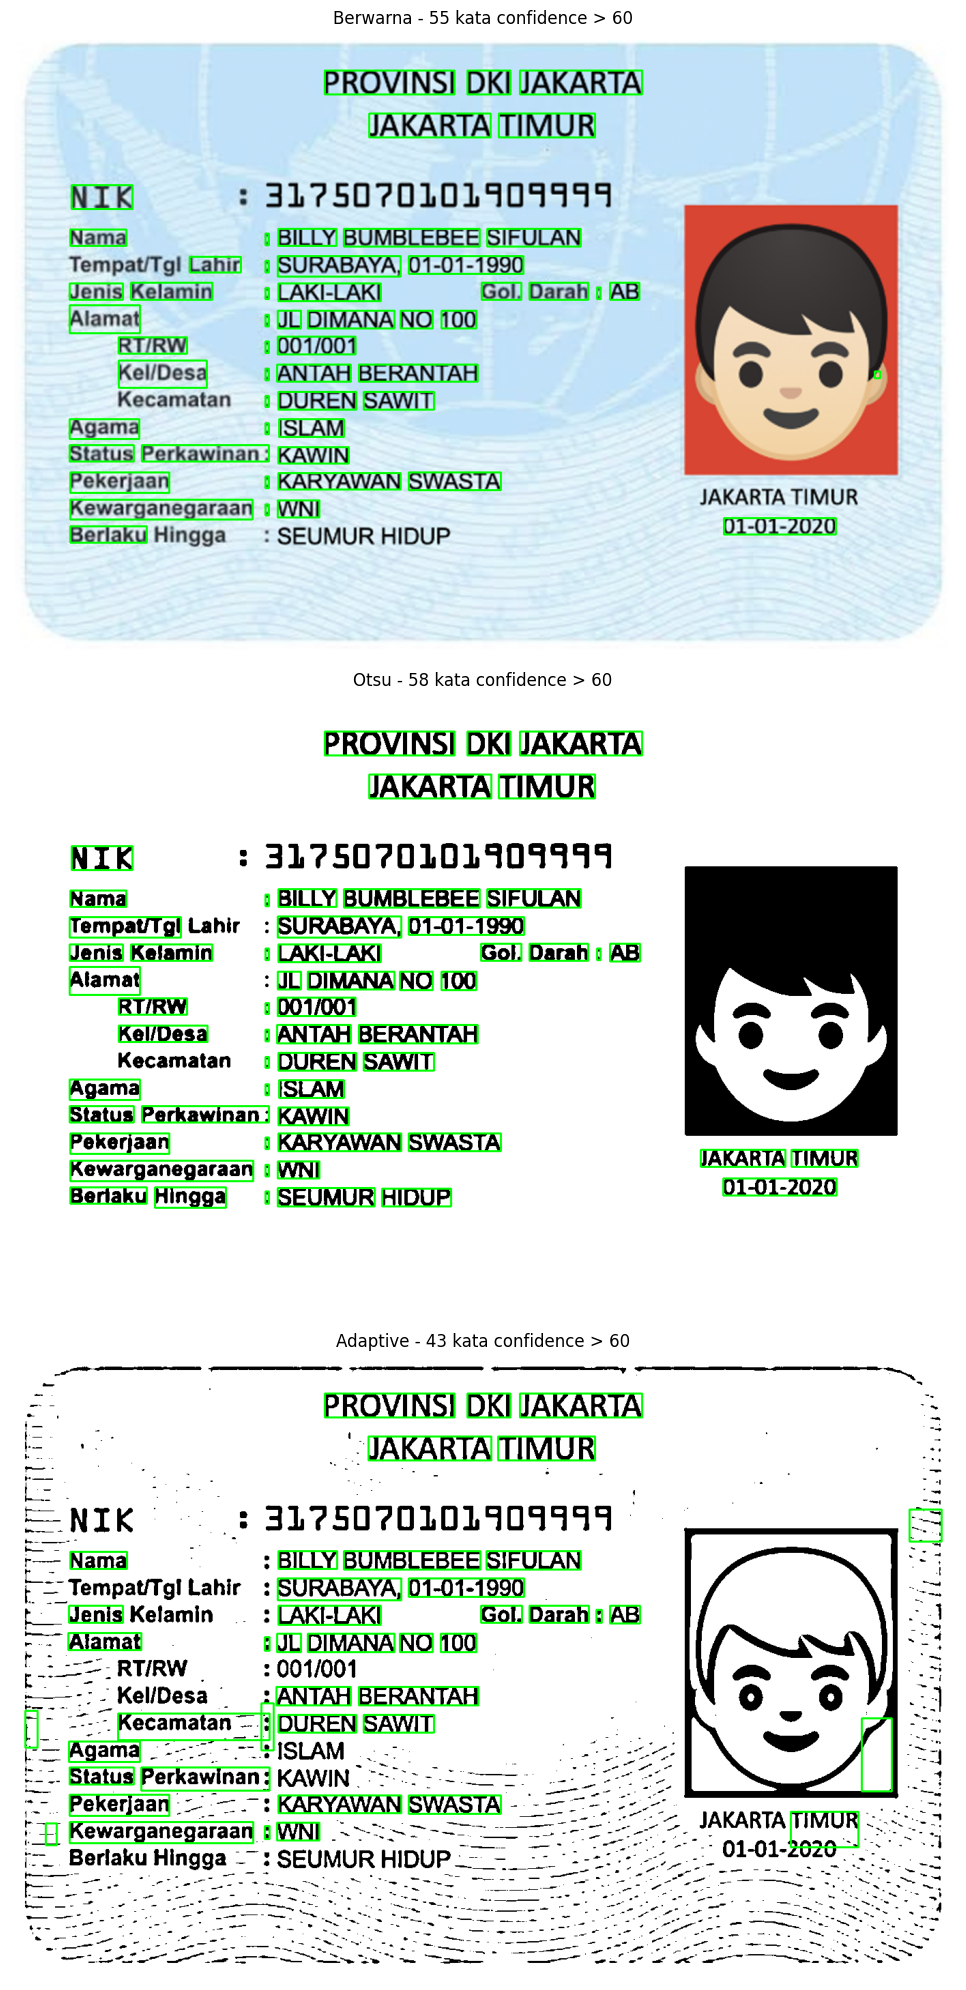

In [23]:
def ocr_boxes(img, conf_min=60):
    if img.ndim == 2:
        rgb = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
    else:
        rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    rgb = np.ascontiguousarray(rgb.copy())

    data = pytesseract.image_to_data(rgb, lang=OCR_LANG,
                                     config="--oem 3 --psm " + str(OCR_PSM),
                                     output_type=pytesseract.Output.DICT)
    kata, confs = [], []
    for i in range(len(data["text"])):
        txt = data["text"][i].strip()
        try:
            conf = float(data["conf"][i])
        except ValueError:
            conf = -1.0
        if txt and conf > conf_min:
            x, y, w, h = (data["left"][i], data["top"][i],
                          data["width"][i], data["height"][i])
            cv.rectangle(rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
            kata.append(txt)
            confs.append(conf)
    return rgb, kata, confs


ringkasan = {}
plt.figure(figsize=(13, 20))
for i, (nama, im) in enumerate(citra_uji.items()):
    kotak, kata, confs = ocr_boxes(im)
    ringkasan[nama] = confs
    plt.subplot(3, 1, i + 1)
    plt.imshow(kotak)
    plt.title(nama + ' - ' + str(len(kata)) + ' kata confidence > 60')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [24]:
ACUAN = ["3175070101909999", "BILLY BUMBLEBEE SIFULAN", "SURABAYA", "01-01-1990",
         "LAKI-LAKI", "AB", "JL DIMANA NO 100", "001/001", "DUREN SAWIT", "SEUMUR HIDUP"]


def normalisasi(s):
    return " ".join(s.upper().split())


print("No | Teks sebenarnya         | Berwarna | Otsu | Adaptive")
print("-" * 66)
cocok = {nama: 0 for nama in citra_uji}
for i, acuan in enumerate(ACUAN, 1):
    tanda = {}
    for nama in citra_uji:
        ok = normalisasi(acuan) in normalisasi(teks[nama])
        tanda[nama] = "v" if ok else "x"
        cocok[nama] += int(ok)
    print("%2d | %-24s | %8s | %4s | %8s" % (i, acuan, tanda['Berwarna'],
                                             tanda['Otsu'], tanda['Adaptive']))

print()
print("Citra masukan     | Item tepat | Kecocokan (%) | Rata-rata confidence")
print("-" * 66)
for nama in citra_uji:
    confs = ringkasan[nama]
    rata = np.mean(confs) if confs else 0.0
    print("%-17s | %10d | %13.0f | %20.1f" % (nama, cocok[nama],
                                              cocok[nama] / len(ACUAN) * 100, rata))

No | Teks sebenarnya         | Berwarna | Otsu | Adaptive
------------------------------------------------------------------
 1 | 3175070101909999         |        x |    v |        x
 2 | BILLY BUMBLEBEE SIFULAN  |        v |    v |        v
 3 | SURABAYA                 |        v |    v |        v
 4 | 01-01-1990               |        v |    v |        v
 5 | LAKI-LAKI                |        v |    v |        v
 6 | AB                       |        v |    v |        v
 7 | JL DIMANA NO 100         |        v |    v |        v
 8 | 001/001                  |        v |    v |        v
 9 | DUREN SAWIT              |        v |    v |        v
10 | SEUMUR HIDUP             |        x |    v |        x

Citra masukan     | Item tepat | Kecocokan (%) | Rata-rata confidence
------------------------------------------------------------------
Berwarna          |          8 |            80 |                 89.6
Otsu              |         10 |           100 |                 88.3
Adaptiv

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat?**

Lihat kolom kecocokan pada tabel. Pada percobaan ini citra berwarna asli dan Otsu memberi
kecocokan tertinggi, sedangkan Adaptive sedikit di bawahnya. Citra berwarna biasanya lebih
baik karena tesseract bekerja pada citra berwarna: tulisan gelap di latar terang tetap
kontras dan tidak ada detail yang hilang. Segmentasi hanya membantu kalau binerisasi
berhasil memisahkan tulisan tanpa membuang detail, misalnya pada KTP yang latarnya sangat
berpola atau pencahayaannya tidak merata. KTP tiap orang berbeda, jadi angka pada tabel
bisa berubah.

**2. Sebutkan minimal dua kesalahan pembacaan.**

- NIK 3175070101909999 terbaca 31?50?01014041419 pada citra berwarna dan
  31?050?70101409949 pada citra Otsu. Digit 0, 9, dan 1 saling tertukar karena
  goresan angkanya rapat.
- Label Tempat/Tgl Lahir terbaca "Tempati gl Lahir" dan Kel/Desa terbaca "KellDesa",
  tanda garis miring hilang atau berubah.

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR?**

Tidak. Di percobaan ini hasil terbaik justru dari citra berwarna. Segmentasi menaikkan
akurasi kalau latar aslinya berpola atau kontras tulisannya rendah, tetapi bisa menurunkan
akurasi kalau threshold menghapus tulisan tipis atau menambah noise di area yang homogen.

**4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**

Latar berpola seperti garis peta, watermark, dan foto dianggap tesseract sebagai kandidat
huruf sehingga muncul teks palsu dan confidence turun. Latar terang dengan tulisan gelap
lebih aman dibandingkan latar gelap dengan tulisan terang.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**

Tidak selalu. Rata-rata confidence hanya dihitung dari kata yang lolos batas confidence,
jadi metode yang mengenali sedikit kata dengan sangat yakin bisa punya rata-rata tinggi
walaupun banyak teks terlewat. Pada tabel ini Otsu memiliki rata-rata confidence tertinggi
tetapi kecocokannya sama dengan citra berwarna, bukan lebih tinggi. Karena itu penilaian
harus melihat kedua kolom sekaligus.